# 04 · Winner's curse and empirical-Bayes correction

The arm with the highest observed CTR is picked *because* it got lucky, so its observed lift overstates its true lift.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import upworthy as uw

pd.set_option("display.max_columns", None)
uw.FIG_DIR.mkdir(parents=True, exist_ok=True)

con = uw.connect()

from scipy import stats

arms = uw.load_arms(con)
phi = uw.estimate_dispersion(uw.per_test_chi2(arms))
arms = uw.add_deviations(arms, phi)
print(f"phi = {phi:.2f}")

phi = 1.83


## 1. Naive winner lift

For every test, take the arm with the highest CTR and compare it with the other arms.

In [2]:
arms["theta_hat"] = 0.0          # placeholder until the EB model is fitted
naive = uw.winner_lifts(arms)

naive.groupby("is_aa")["naive_lift"].describe()[["count", "mean", "50%"]].round(3)

,count,mean,50%
is_aa,,,
False,3176.0,0.468,0.407
True,646.0,0.291,0.248


In A/A tests the true lift is exactly zero, yet the naive winner still shows a large lift. That gap is pure winner's curse.

## 2. Empirical-Bayes model

Each arm's true effect θ is drawn from a prior learned from all tests:

θ ~ π₀ · (exactly 0) + (1 − π₀) · Normal(0, τ²)

The observed deviation is θ plus noise with variance φ · p(1 − p) / n.
Fitting π₀ and τ by maximum likelihood across ~15,000 arms tells us how big real effects usually are.
The posterior mean of θ is the shrunken estimate.

In [3]:
real_arms = arms[~arms["is_aa"]]
pi0, tau2 = uw.fit_spike_slab(real_arms["dev_scaled"], real_arms["noise_var"])

typical_ctr = arms["clicks"].sum() / arms["impressions"].sum()
print(f"Share of arms with no real effect (pi0): {pi0:.0%}")
print(f"Size of real effects (tau), relative to CTR: {np.sqrt(tau2) / typical_ctr:.0%}")

Share of arms with no real effect (pi0): 79%
Size of real effects (tau), relative to CTR: 39%


**Sanity check:** fitting the same model to A/A tests alone should find almost no real effects.

In [4]:
aa_arms = arms[arms["is_aa"]]
pi0_aa, tau2_aa = uw.fit_spike_slab(aa_arms["dev_scaled"], aa_arms["noise_var"])
print(f"A/A tests: share of arms with no real effect = {pi0_aa:.0%}")

A/A tests: share of arms with no real effect = 98%


## 3. Corrected winner lift

In [5]:
arms["theta_hat"], arms["p_real"] = uw.posterior_mean(
    arms["dev_scaled"], arms["noise_var"], pi0, tau2
)
winners = uw.winner_lifts(arms)

result = winners.groupby("is_aa")[["naive_lift", "eb_lift"]].agg(["mean", "median"]).round(3)
result.index = result.index.map({False: "real tests", True: "A/A tests (true lift = 0)"})
result

naive_lift        eb_lift       
                                mean median    mean median
is_aa                                                     
real tests                     0.468  0.407   0.187  0.085
A/A tests (true lift = 0)      0.291  0.248   0.073  0.037

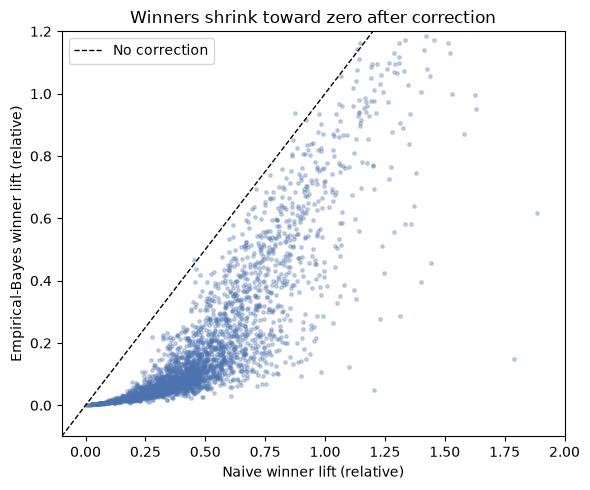

In [6]:
fig, ax = plt.subplots(figsize=(6, 5))
w = winners[~winners["is_aa"]]
ax.scatter(w["naive_lift"], w["eb_lift"], s=6, alpha=0.3, color="#4C72B0")
lim = [-0.1, 2]
ax.plot(lim, lim, color="black", linestyle="--", linewidth=1, label="No correction")
ax.set_xlim(lim); ax.set_ylim(-0.1, 1.2)
ax.set_xlabel("Naive winner lift (relative)")
ax.set_ylabel("Empirical-Bayes winner lift (relative)")
ax.set_title("Winners shrink toward zero after correction")
ax.legend()
fig.tight_layout()
fig.savefig(uw.FIG_DIR / "winner_shrinkage.png", dpi=150)
plt.show()

## 4. Validation by simulation

Simulate tests with the same sizes and CTRs as the real ones, where the true lifts are known, and check which estimate is closer to the truth.

In [7]:
sim = uw.simulate_winners(real_arms.assign(theta_hat=0.0), pi0, tau2, phi, seed=42)

bias = (sim[["naive_lift", "eb_lift"]].mean() - sim["true_lift"].mean())
rmse = np.sqrt(((sim[["naive_lift", "eb_lift"]].sub(sim["true_lift"], axis=0)) ** 2).mean())
pd.DataFrame({
    "average estimate": sim[["naive_lift", "eb_lift"]].mean(),
    "average true lift": sim["true_lift"].mean(),
    "bias": bias,
    "RMSE": rmse,
}).round(3)

,average estimate,average true lift,bias,RMSE
naive_lift,0.498,0.245,0.253,0.457
eb_lift,0.233,0.245,-0.012,0.362


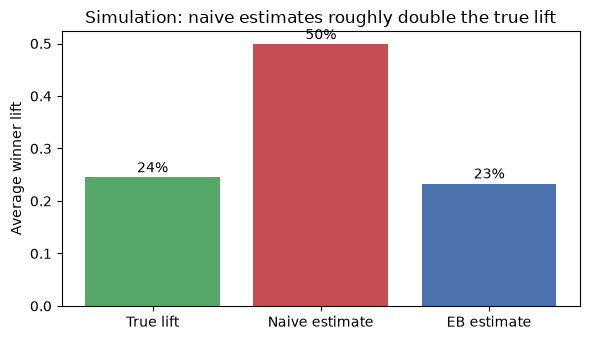

In [8]:
fig, ax = plt.subplots(figsize=(6, 3.5))
labels = ["True lift", "Naive estimate", "EB estimate"]
values = [sim["true_lift"].mean(), sim["naive_lift"].mean(), sim["eb_lift"].mean()]
ax.bar(labels, values, color=["#55A868", "#C44E52", "#4C72B0"])
for i, v in enumerate(values):
    ax.text(i, v + 0.01, f"{v:.0%}", ha="center")
ax.set_ylabel("Average winner lift")
ax.set_title("Simulation: naive estimates roughly double the true lift")
fig.tight_layout()
fig.savefig(uw.FIG_DIR / "simulation_bias.png", dpi=150)
plt.show()

## 5. Takeaways

1. **Reported wins are inflated.** The naive winner lift is roughly 2.5× the bias-corrected estimate on real tests.
2. **Luck alone produces big "wins".** In A/A tests, where nothing differs, naive winners still show a large lift.
3. **Empirical Bayes fixes most of the bias.** In simulation the corrected estimate is close to the true lift, while the naive one is about double.

**Recommendations for an experimentation team**
- Report shrunken (EB) lifts, not raw winner lifts, when forecasting impact.
- Calibrate tests with periodic A/A runs and correct for overdispersion before computing p-values.
- Size tests for the effects that actually occur, or accept that most tests can only detect very large lifts.
- Control the false discovery rate when many tests run in parallel.